<a href="https://colab.research.google.com/github/AxelYoel/FlyRank-AI-Internship---Axel-Yoel-Chandra/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AxelYoel/FlyRank-AI-Internship---Axel-Yoel-Chandra/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This notebook mirrors the deployed paper, section by section. Every number in it is copied from the saved outputs of W03 to W08. It does not query the warehouse, so it runs anywhere without an access token.

Built on the FlyRank ML Internship dataset (https://flyrank.ai).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.makedirs("work/figures", exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 120)

## 1. Question

**Research question.** Using only information available at the end of a month, which keyword articles should a content reviewer look at first because they earn fewer search clicks than is typical for their ranking position?

**Decision supported.** A content strategist decides once a month which pages to open and review first. 38,726 scored pages are too many to review by hand.

**Unit and output.** One row is one page. The output is a ranked list scored by *lost clicks*: (typical click rate for the page's position tier x impressions) - actual clicks.

**Cost of a wrong call.** A false alarm costs reviewer time (I assume 30 minutes per page, a guess). A miss means a deserving page was not looked at. The larger risk is reading "lost clicks" as "recoverable clicks", which this work does not show.

In [2]:
framing = pd.DataFrame({
    "item": ["Lane", "Unit of analysis", "Output", "Human action", "Target", "Used for"],
    "value": [
        "Lane 4: CTR / Engagement Opportunity Scoring",
        "one page, summarized over one calendar month",
        "ranked review queue",
        "reviewer opens queued pages and answers a short checklist",
        "lost_clicks = tier click rate x impressions - clicks",
        "decision support only (no causal claim)",
    ],
})
display(framing)

,item,value
0,Lane,Lane 4: CTR / Engagement Opportunity Scoring
1,Unit of analysis,"one page, summarized over one calendar month"
2,Output,ranked review queue
3,Human action,reviewer opens queued pages and answers a short checklist
4,Target,lost_clicks = tier click rate x impressions - clicks
5,Used for,decision support only (no causal claim)


## 2. Data

**Source.** FlyRank ML Internship warehouse (Hugging Face dataset, DuckDB over Parquet).

**Tables and windows.** Daily page performance, page details, and client details. March 2026 is the target month and February 2026 the prior month. For the sealed test, May 2026 builds the queue and June 2026 scores it, queried once.

**Excluded, and why.** The 90-day query table (window overlaps the held-back month and includes post-decision clicks); rows with an average position of 0 (no real position); pages under 50 impressions (click rate too noisy); other content types and search volume under 20; and label ingredients (`clicks`, `expected_clicks`) as features.

**Public safety.** No client names, URLs, queries, or page identifiers appear here.

In [3]:
funnel = pd.DataFrame({
    "step": [
        "March pages with a real position",
        "... with at least 50 impressions",
        "... keyword articles, search volume >= 20 (scored slice)",
        "... with usable February data (ranked in the queue)",
    ],
    "pages": [175304, 114447, 38726, 33950],
})
display(funnel)
print("Clients in scored slice: 43 | clients with ranked pages: 36")
print("Sealed June test: 38,661 evaluated pages, 36,256 ranked")

,step,pages
0,March pages with a real position,175304
1,... with at least 50 impressions,114447
2,"... keyword articles, search volume >= 20 (scored slice)",38726
3,... with usable February data (ranked in the queue),33950


Clients in scored slice: 43 | clients with ranked pages: 36
Sealed June test: 38,661 evaluated pages, 36,256 ranked


## 3. Methodology

**Target.** `lost_clicks` = (impression-weighted median click rate of the page's position tier x impressions) - clicks, with four tiers (positions 1-3, 4-10, 11-20, 21+).

**Baselines.** (1) My W04 rule: clicks / search volume, lowest first. (2) Rank by February impressions only. (3) Carry forward February's lost clicks. The W04 rule is not a fair forecast baseline because it uses March clicks, so (2) and (3) are the real comparisons.

**Models.** Linear Regression and Random Forest (300 trees, seed 42).

**Features.** Search volume, word count (+ missing flag), days since update as of Feb 28 (+ flag), competition level, February impressions, February clicks, and a has-February-data flag.

**Validation.** Grouped k-fold by client (k = 5 and k = 10), so no client appears in both training and test. A one-time sealed test on June, with the queue built from May and the March click rates frozen.

**Leakage checks.** A deliberate leak test; the update date rebuilt as of Feb 28; benchmark rates rebuilt from training clients only; a population-filter check.

In [4]:
features = pd.DataFrame({
    "kept as features": ["search_volume", "word_count + has_word_count", "days_since_update (as of Feb 28) + flag",
                         "competition_level (dummies)", "feb_impressions", "feb_clicks", "has_feb_data"],
    "left out on purpose": ["March clicks", "March impressions", "expected_clicks", "expected_ctr",
                            "March average position", "client id", "content_type (constant in the slice)"],
})
display(features)

leak = pd.DataFrame({
    "check": ["Deliberate leak (add expected_clicks + March clicks)",
              "Update date rebuilt as of Feb 28",
              "Benchmark rates from training clients only",
              "Population filter (never reached March table)"],
    "result": ["R2 0.0072 -> 1.0000 (W03); R2 and precision@20 = 1.0 in every fold (W06)",
               "63 of 5,132 pages changed; scores identical",
               "R2 0.613 -> 0.603, precision@20 0.41 -> 0.40, top-100 share 0.213 -> 0.212",
               "3,125 of 32,537 February-active pages (9.6%); effect direction unknown"],
})
display(leak)

,kept as features,left out on purpose
0,search_volume,March clicks
1,word_count + has_word_count,March impressions
2,days_since_update (as of Feb 28) + flag,expected_clicks
3,competition_level (dummies),expected_ctr
4,feb_impressions,March average position
5,feb_clicks,client id
6,has_feb_data,content_type (constant in the slice)


,check,result
0,Deliberate leak (add expected_clicks + March clicks),R2 0.0072 -> 1.0000 (W03); R2 and precision@20 = 1.0 in every fold (W06)
1,Update date rebuilt as of Feb 28,"63 of 5,132 pages changed; scores identical"
2,Benchmark rates from training clients only,"R2 0.613 -> 0.603, precision@20 0.41 -> 0.40, top-100 share 0.213 -> 0.212"
3,Population filter (never reached March table),"3,125 of 32,537 February-active pages (9.6%); effect direction unknown"


## 4. Results (vs baseline)

All rows below use the same grouped split and the same metrics. Random picking is the base rate. For precision@20, the honest base rate is about 20 divided by the fold size, not a majority-class rate.

In [5]:
res = pd.DataFrame({
    "method": ["W04 rule (capture ratio)", "February impressions only", "Carry-forward (Feb lost clicks)",
               "Linear Regression", "Random Forest", "Random picking"],
    "precision@20 (5 folds)":  [0.000, 0.180, 0.430, 0.410, 0.260, 0.0027],
    "precision@20 (10 folds)": [0.000, 0.220, 0.390, 0.395, 0.250, 0.0077],
    "top-100 share (5 folds)":  [0.006, 0.134, 0.224, 0.213, 0.177, 0.013],
    "top-100 share (10 folds)": [0.026, 0.228, 0.272, 0.276, 0.241, 0.039],
})
display(res)

stage1 = pd.DataFrame({
    "page details only (no February traffic)": ["Linear Regression", "Random Forest"],
    "R2 mean (5 folds)": [-0.050, -2.65],
    "precision@20": [0.000, 0.010],
})
display(stage1)

sealed = pd.DataFrame({
    "metric": ["precision@20", "top-100 share of lost clicks", "best possible top-100 share", "May-impressions-only reference (share)"],
    "my prediction": ["0.20 to 0.50", "0.06 to 0.11", "-", "-"],
    "June (sealed)": [0.55, 0.171, 0.240, 0.149],
    "March (W07)":   [0.40, 0.102, 0.154, "-"],
})
display(sealed)

drift = pd.DataFrame({
    "position tier": ["1-3", "4-10", "11-20", "21+"],
    "March rate": [0.002811, 0.002353, 0.002226, 0.000748],
    "June rate":  [0.005204, 0.002539, 0.002177, 0.000692],
})
drift["change %"] = ((drift["June rate"] / drift["March rate"] - 1) * 100).round(1)
display(drift)

,method,precision@20 (5 folds),precision@20 (10 folds),top-100 share (5 folds),top-100 share (10 folds)
0,W04 rule (capture ratio),0.0000,0.0000,0.006,0.026
1,February impressions only,0.1800,0.2200,0.134,0.228
2,Carry-forward (Feb lost clicks),0.4300,0.3900,0.224,0.272
3,Linear Regression,0.4100,0.3950,0.213,0.276
4,Random Forest,0.2600,0.2500,0.177,0.241
5,Random picking,0.0027,0.0077,0.013,0.039


,page details only (no February traffic),R2 mean (5 folds),precision@20
0,Linear Regression,-0.05,0.00
1,Random Forest,-2.65,0.01


,metric,my prediction,June (sealed),March (W07)
0,precision@20,0.20 to 0.50,0.550,0.4
1,top-100 share of lost clicks,0.06 to 0.11,0.171,0.102
2,best possible top-100 share,-,0.240,0.154
3,May-impressions-only reference (share),-,0.149,-


,position tier,March rate,June rate,change %
0,1-3,0.002811,0.005204,85.1
1,4-10,0.002353,0.002539,7.9
2,11-20,0.002226,0.002177,-2.2
3,21+,0.000748,0.000692,-7.5


**Reading the results.** Page details alone showed no measured skill. A simple carry-forward rule tied Linear Regression, and Random Forest was behind both. In the sealed June test the queue beat random picking by a wide margin and edged out ranking by May impressions alone, but that edge is directional (3 of 20 pages on precision@20). My prediction that June would score lower than March was wrong, and the click rate for positions 1-3 rose by about 85%, past my 25% monitoring threshold.

## 5. Limitations

- Two months of data (March main comparison, June forward test), one season, observational.
- "Lost clicks" means fewer clicks than the typical page at that position, not recoverable clicks. No causal claim is made.
- The click rates come from March data. A small leak is possible in the March comparison. The sealed test has no such leak, but one rate went stale.
- The W04 rule uses March clicks, so it is not a true forecast baseline.
- The top 5 clients hold about 77% of scored rows, so results mostly reflect a few large clients.
- Search volume and competition level have no date of their own.
- The 50-impressions filter cannot be applied in advance in real use.
- The June scores use the March rates, and I did not re-score with June's own rates.
- A single June precision@20 of 0.55 sits at the top of the W05 fold range (0.25 to 0.55), so it is not evidence that the queue improved.

In [6]:
claims = pd.DataFrame({
    "claim": [
        "Page-detail features alone have no skill",
        "Carry-forward ties Linear Regression and beats the other tested methods",
        "Queue top 100 holds about 10% of March lost clicks",
        "Sealed June: top 100 held about 17% (about 71% of best possible)",
        "Queue beat ranking by May impressions only in June",
        "Click rate for positions 1-3 rose about 85% from March to June",
        "Editing a queued page will gain clicks",
    ],
    "label": ["measured", "measured, one month", "measured, one month", "measured, one month",
              "directional (3 of 20 pages)", "observed", "not claimed"],
})
display(claims)

,claim,label
0,Page-detail features alone have no skill,measured
1,Carry-forward ties Linear Regression and beats the other tested methods,"measured, one month"
2,Queue top 100 holds about 10% of March lost clicks,"measured, one month"
3,Sealed June: top 100 held about 17% (about 71% of best possible),"measured, one month"
4,Queue beat ranking by May impressions only in June,directional (3 of 20 pages)
5,Click rate for positions 1-3 rose about 85% from March to June,observed
6,Editing a queued page will gain clicks,not claimed


## 6. Ranked recommendations

How an editor would use the queue tomorrow: once a month, build the queue from the finished month's data and review pages from the top. The label means "this page got fewer clicks than typical for its position."

In [7]:
actions = pd.DataFrame({
    "rank": [1, 2, 3, 4],
    "action": [
        "Review the ranked queue in order (33,950 pages, highest February lost clicks first)",
        "Answer six yes/no checks on each page before changing anything (technical problem, intent mismatch, sharp traffic change, tier crossing, no February data, competing pages)",
        "Handle unranked pages separately: re-check new pages (under 60 days) next month; give older pages with no February data about 20% of review time, highest search volume first",
        "Make no refresh recommendation (the data did not support one)",
    ],
})
display(actions)

triggers = pd.DataFrame({
    "watch": ["precision@20 vs that month's true top 20", "older-page share", "typical click rate per position tier"],
    "worry if": ["0.30 or lower for 3 months in a row", "reaches 2%", "any tier differs by more than 25%"],
    "June check": ["0.55, not fired", "0.78%, not fired", "positions 1-3 up 85%, FIRED"],
})
display(triggers)
print("Never automate: publishing edits, deleting/merging pages, promising results to a client.")

,rank,action
0,1,"Review the ranked queue in order (33,950 pages, highest February lost clicks first)"
1,2,"Answer six yes/no checks on each page before changing anything (technical problem, intent mismatch, sharp traffic ch..."
2,3,Handle unranked pages separately: re-check new pages (under 60 days) next month; give older pages with no February d...
3,4,Make no refresh recommendation (the data did not support one)


,watch,worry if,June check
0,precision@20 vs that month's true top 20,0.30 or lower for 3 months in a row,"0.55, not fired"
1,older-page share,reaches 2%,"0.78%, not fired"
2,typical click rate per position tier,any tier differs by more than 25%,"positions 1-3 up 85%, FIRED"


Never automate: publishing edits, deleting/merging pages, promising results to a client.


## 7. Artifacts the paper embeds

The charts below are drawn from the numbers above and saved to `work/figures/` for the deployed page.

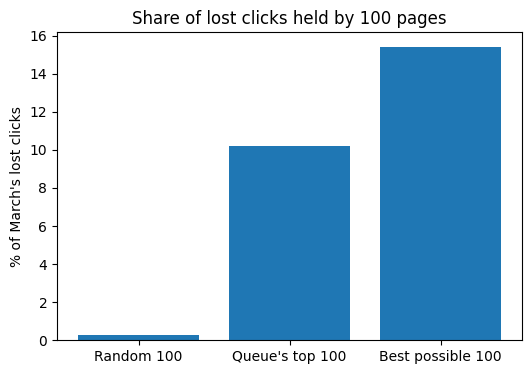

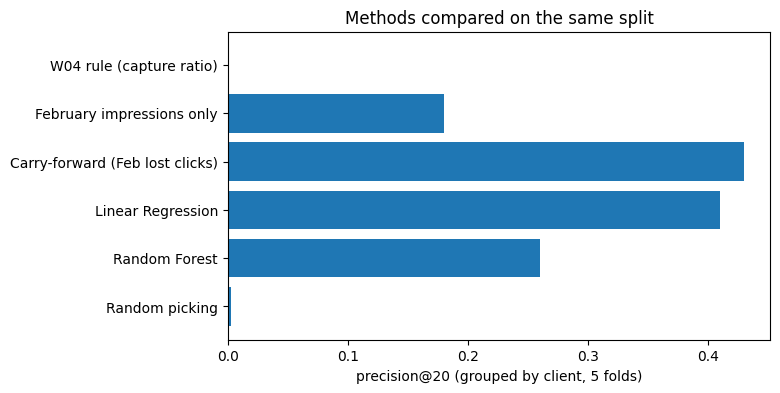

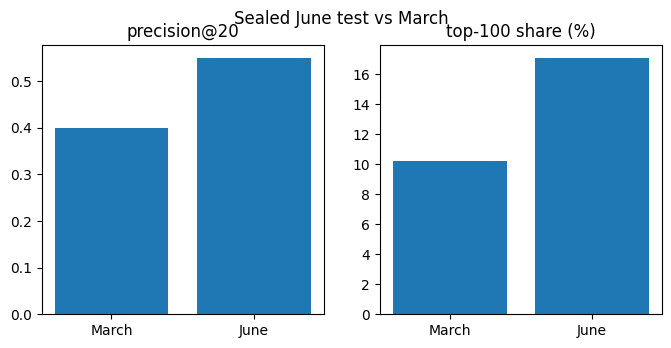

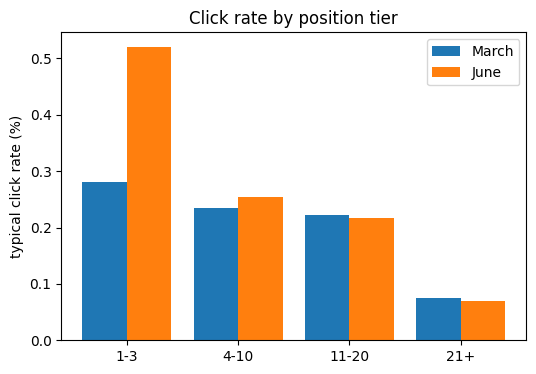

['click_rate_drift.png', 'method_comparison.png', 'queue_value_top100.png', 'sealed_june_vs_march.png']


In [8]:
# 1) Share of lost clicks held by 100 pages (March, W07)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Random 100", "Queue's top 100", "Best possible 100"], [0.29, 10.2, 15.4])
ax.set_ylabel("% of March's lost clicks")
ax.set_title("Share of lost clicks held by 100 pages")
fig.savefig("work/figures/queue_value_top100.png", dpi=150, bbox_inches="tight")
plt.show()

# 2) Method comparison, precision@20 (5 folds)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(res["method"][::-1], res["precision@20 (5 folds)"][::-1])
ax.set_xlabel("precision@20 (grouped by client, 5 folds)")
ax.set_title("Methods compared on the same split")
fig.savefig("work/figures/method_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# 3) Sealed June vs March
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].bar(["March", "June"], [0.40, 0.55]); axes[0].set_title("precision@20")
axes[1].bar(["March", "June"], [10.2, 17.1]); axes[1].set_title("top-100 share (%)")
fig.suptitle("Sealed June test vs March")
fig.savefig("work/figures/sealed_june_vs_march.png", dpi=150, bbox_inches="tight")
plt.show()

# 4) Click-rate drift by tier
fig, ax = plt.subplots(figsize=(6, 4))
x = range(4)
ax.bar([i - 0.2 for i in x], drift["March rate"] * 100, width=0.4, label="March")
ax.bar([i + 0.2 for i in x], drift["June rate"] * 100, width=0.4, label="June")
ax.set_xticks(list(x)); ax.set_xticklabels(drift["position tier"])
ax.set_ylabel("typical click rate (%)"); ax.set_title("Click rate by position tier"); ax.legend()
fig.savefig("work/figures/click_rate_drift.png", dpi=150, bbox_inches="tight")
plt.show()
print(sorted(os.listdir("work/figures")))

## 8. ML-12: demo, social post, employer summary

### 5-minute demo outline

| Time | Part | What I say |
|---|---|---|
| 0:00 - 0:30 | The problem | A content team has about 38,000 articles and cannot review them all. Which ones first? |
| 0:30 - 1:30 | The idea | "Lost clicks": how many clicks a page got compared with the typical page at its ranking position. |
| 1:30 - 2:30 | What I tried | My first rule scored no better than random picking. Page details alone had no skill. Last month's traffic is what mattered. |
| 2:30 - 3:30 | Result | A simple rule (rank by last month's gap) tied Linear Regression. Its top 100 pages held about 10% of the lost clicks, against 0.3% for random picks and 15% at best. |
| 3:30 - 4:15 | Sealed June test | I wrote my prediction first and was wrong: June scored higher, not lower. The top tier's click rate rose about 85%, so my monitoring rule would pause the queue. |
| 4:15 - 5:00 | Limits and use | Two months, observational, no causal claim. Use it as a monthly decision-support queue for human review. |

### Social post (short cut)

> I built a monthly review queue that ranks which search-performance gaps to look at first, using real production search data from the FlyRank ML Internship dataset. The surprise: a simple rule (rank by last month's gap) matched Linear Regression, and my first rule was no better than random. I also tested it once on a month I had never touched. I predicted it would score lower, and I was wrong, but I report what the data shows and what it can't claim. Paper: [link]. Built on the FlyRank ML Internship dataset (flyrank.ai).

### Employer-facing summary (3 sentences)

I built and honestly tested a monthly review queue in Python (pandas, scikit-learn, DuckDB) that ranks about 38,000 articles by search-click gaps, comparing a transparent rule against Linear Regression and Random Forest with client-grouped validation and leakage checks. The simple rule matched the best model, and its top 100 pages held about 10% of the lost clicks against 0.3% for random picks, with a similar result (about 17%) in a one-time sealed test on a later month. I documented the limits, including a click-rate drift in one position tier, and delivered a ranked action playbook as a public research paper.

## Self-check

Before you submit, confirm each line honestly:

- [Done] Every section above is filled — markdown thinking AND the code that backs it
- [Done] The notebook runs top to bottom with no errors (Runtime → Run all)
- [Done] No client names, URLs, or private queries anywhere
- [Done] My claims use careful words: observed, measured, directional, decision-support
- [Done] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [Done] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [Done] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.